# Setting loader and plot kwargs

A component takes two kinds of arguments:

- **loader args** decide what data is loaded (e.g. `signal_file`); they are listed in the component signature (`help(Component)`).
- **plot kwargs** are everything else; they go to the component's `_plot` (e.g. `color`), plus `axes_kwargs` for `ax.set_*`.

Both can be set at several levels; below is an example for each. The displays show which value is used and where it was set (see [Debugging.ipynb](Debugging.ipynb)). Two density tracks: AG95384 and AG95451.

In [1]:
import matplotlib.pyplot as plt
from genome_tools import GenomicInterval
from genome_tools.plotting.modular_plot import IntervalPlotter
from genome_tools.plotting.modular_plot.plot_components.basic import TrackComponent, SegmentsTabixComponent

base = 'https://regulome.altius.org/data/per_sample'
density_bw = f'{base}/AG95384/AG95384.normalized_density.bw'
density_bw2 = f'{base}/AG95451/AG95451.normalized_density.bw'
peaks = f'{base}/AG95384/peaks/fdr0.05/AG95384.peaks.fdr0.05.bed.gz'
interval = GenomicInterval.from_ucsc('chr2:60450000-60540000')

## Loader args

Priority, low to high (a later one wins). Everything set at init is overridden by runtime kwargs:

1. loader default (in the loader's `_load` signature)
2. `IntervalPlotter(**kwargs)`
3. component kwarg
4. loader-specific override on the component: `Component(SignalLoader={...})`
5. `get_interval_data(**kwargs)` / `plot(..., loaders_kwargs=...)`: all components
6. `get_interval_data(ComponentName={...})`: one component
7. loader-specific override at runtime: `get_interval_data(SignalLoader={...})`, or `get_interval_data(ComponentName={'SignalLoader': {...}})` for one component

Levels 1-4 are shown with the plotter display (where each value was set), levels 5-7 with the loading workflow (what `get_interval_data` will read with these runtime kwargs).

### 1. Loader default

Args with a default in the loader's `_load` signature, here `extra_columns` etc. of `SegmentsTabixLoader`:

In [2]:
IntervalPlotter([SegmentsTabixComponent(name='Peaks', tabix_file=peaks)])

**IntervalPlotter** · width 2.5 · height 1.2

| # | Component | Class | Height | interval_key | Attached loaders |
|---|---|---|---|---|---|
| 1 | Peaks | `SegmentsTabixComponent` | 1 | — | SegmentsTabixLoader |

<details><summary><b>Peaks</b>: <code>SegmentsTabixComponent</code> · height 1 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SegmentsTabixLoader` | `tabix_file` | `'https://regulome.altius…84.peaks.fdr0.05.bed.gz'` | component |
|  | `extra_columns` | `None` | default |
|  | `rectprops_columns` | `None` | default |
|  | `tabix_column_names` | `None` | default |

</details>

### 2. `IntervalPlotter(**kwargs)`

Used by every component that doesn't set its own:

In [3]:
IntervalPlotter(
    [TrackComponent(name='AG95384', height=0.5), TrackComponent(name='AG95451', height=0.5)],
    signal_file=density_bw,
)

Found overlapping component loader kwargs:
Argument 'signal_file' used by: AG95384, AG95451


**IntervalPlotter** · width 2.5 · height 1.4 · loader args: `signal_file`

| # | Component | Class | Height | interval_key | Attached loaders |
|---|---|---|---|---|---|
| 1 | AG95384 | `TrackComponent` | 0.5 | — | SignalLoader |
| 2 | AG95451 | `TrackComponent` | 0.5 | — | SignalLoader |

<details><summary><b>AG95384</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | plotter |

</details>

<details><summary><b>AG95451</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | plotter |

</details>

### 3. Component kwarg

Overrides the plotter value for this component:

In [4]:
IntervalPlotter(
    [TrackComponent(name='AG95384', height=0.5), TrackComponent(name='AG95451', height=0.5, signal_file=density_bw2)],
    signal_file=density_bw,
)

Found overlapping component loader kwargs:
Argument 'signal_file' used by: AG95384, AG95451


**IntervalPlotter** · width 2.5 · height 1.4 · loader args: `signal_file`

| # | Component | Class | Height | interval_key | Attached loaders |
|---|---|---|---|---|---|
| 1 | AG95384 | `TrackComponent` | 0.5 | — | SignalLoader |
| 2 | AG95451 | `TrackComponent` | 0.5 | — | SignalLoader |

<details><summary><b>AG95384</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | plotter |

</details>

<details><summary><b>AG95451</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…1.normalized_density.bw'` | component |

</details>

### 4. Loader-specific override on the component

A dict under the loader name: only that loader gets it (useful when two loaders of a component share an argument name). Overrides the component kwarg:

In [5]:
plotter = IntervalPlotter(
    [
        TrackComponent(name='AG95384', height=0.5),
        TrackComponent(name='AG95451', height=0.5, signal_file=density_bw, SignalLoader={'signal_file': density_bw2}),
    ],
    signal_file=density_bw,
)
plotter

Found overlapping component loader kwargs:
Argument 'signal_file' used by: AG95384, AG95451


**IntervalPlotter** · width 2.5 · height 1.4 · loader args: `signal_file`

| # | Component | Class | Height | interval_key | Attached loaders |
|---|---|---|---|---|---|
| 1 | AG95384 | `TrackComponent` | 0.5 | — | SignalLoader |
| 2 | AG95451 | `TrackComponent` | 0.5 | — | SignalLoader |

<details><summary><b>AG95384</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | plotter |

</details>

<details><summary><b>AG95451</b>: <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1</summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…1.normalized_density.bw'` | component (`SignalLoader` override) |

</details>

### 5. Runtime, all components

Overrides everything set at init, including the `SignalLoader` override of AG95451: both read the AG95384 file.

In [6]:
plotter.get_loading_workflow(interval, signal_file=density_bw)

Found 1 overlapping self.loaders_kwargs (passed in init) and loaders kwargs (from get_interval_data): ['signal_file']


Using values passed to get_interval_data function.


**LoadingWorkflow** · 2 components, 1 loader calls (2 without cache)

- `chr2:60,450,000-60,540,000` · **AG95384**; **AG95451**
  - 1\. `SignalLoader` · **AG95384**; **AG95451** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`

### 6. Runtime, one component

A dict under the component name; overrides the runtime value for all components:

In [7]:
plotter.get_loading_workflow(interval, signal_file=density_bw, AG95451={'signal_file': density_bw2})

Found 1 overlapping self.loaders_kwargs (passed in init) and loaders kwargs (from get_interval_data): ['signal_file']


Using values passed to get_interval_data function.


**LoadingWorkflow** · 2 components, 2 loader calls (2 without cache)

- `chr2:60,450,000-60,540,000` · **AG95384**
  - 1\. `SignalLoader` · **AG95384** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`
- `chr2:60,450,000-60,540,000` · **AG95451**
  - 1\. `SignalLoader` · **AG95451** · `signal_file`=`'https://regulome.altius…1.normalized_density.bw'`

### 7. Runtime loader-specific override

For all components using the loader: overrides even the runtime value for one component (here both read AG95451):

In [8]:
plotter.get_loading_workflow(interval, AG95384={'signal_file': density_bw}, SignalLoader={'signal_file': density_bw2})

**LoadingWorkflow** · 2 components, 1 loader calls (2 without cache)

- `chr2:60,450,000-60,540,000` · **AG95384**; **AG95451**
  - 1\. `SignalLoader` · **AG95384**; **AG95451** · `signal_file`=`'https://regulome.altius…1.normalized_density.bw'`

For one component: a loader dict inside the component dict:

In [9]:
plotter.get_loading_workflow(interval, signal_file=density_bw, AG95451={'SignalLoader': {'signal_file': density_bw2}})

Found 1 overlapping self.loaders_kwargs (passed in init) and loaders kwargs (from get_interval_data): ['signal_file']


Using values passed to get_interval_data function.


**LoadingWorkflow** · 2 components, 2 loader calls (2 without cache)

- `chr2:60,450,000-60,540,000` · **AG95384**
  - 1\. `SignalLoader` · **AG95384** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`
- `chr2:60,450,000-60,540,000` · **AG95451**
  - 1\. `SignalLoader` · **AG95451** · `signal_file`=`'https://regulome.altius…1.normalized_density.bw'`

## Plot kwargs

Priority, low to high (a later one wins):

1. component kwarg
2. `plot_interval(data, **kwargs)`: all components
3. `plot_interval(data, ComponentName={...})`: one component

In [10]:
plotter = IntervalPlotter(
    [
        TrackComponent(name='AG95384', height=0.5, margins=(0, 0.1), color='tab:blue'),
        TrackComponent(name='AG95451', height=0.5, margins=(0.1, 0), color='tab:blue', signal_file=density_bw2),
    ],
    signal_file=density_bw,
)
data = plotter.get_interval_data(interval)

Found overlapping component loader kwargs:
Argument 'signal_file' used by: AG95384, AG95451


Loading data:   0%|          | 0/2 [00:00<?, ?it/s]

Loading data:  50%|█████     | 1/2 [00:06<00:06,  6.91s/it]

Loading data: 100%|██████████| 2/2 [00:14<00:00,  7.37s/it]

Loading data: 100%|██████████| 2/2 [00:14<00:00,  7.30s/it]

### 1. Component kwarg

Both tracks blue, as set on the components:

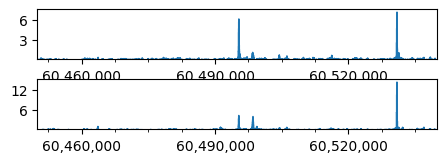

In [11]:
axes = plotter.plot_interval(data, fig_width=4)

### 2. `plot_interval(data, **kwargs)`

Overrides the component kwargs for all components:

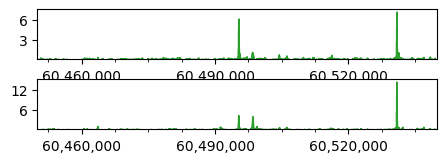

In [12]:
axes = plotter.plot_interval(data, fig_width=4, color='tab:green')

### 3. `plot_interval(data, ComponentName={...})`

Overrides the value for all components, for one component:

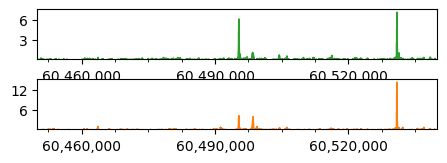

In [13]:
axes = plotter.plot_interval(data, fig_width=4, color='tab:green', AG95451={'color': 'tab:orange'})

## Axes

`axes_kwargs` calls `ax.set_<name>` after plotting (`ylim`, `ylabel`, `yticks`, ...): on the component or per component at plot time. The returned axes (one per component) can also be changed directly.

(0.0, 8.0)

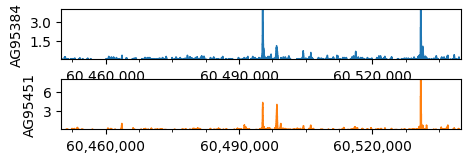

In [14]:
axes = plotter.plot_interval(
    data, fig_width=4,
    AG95384={'axes_kwargs': {'ylim': (0, 4), 'ylabel': 'AG95384'}},
    AG95451={'color': 'tab:orange', 'axes_kwargs': {'ylabel': 'AG95451'}},
)
axes.AG95451.set_ylim(0, 8)

## Size and placement

Component `height` and `margins` are in inches. `fig_width`, `fig_height` and `height_scale` set the figure size; `subplot_spec` draws into a cell of an existing figure instead (the size args are then ignored). The first and last tracks have no outer margins (`margins=(0, 0.1)` / `(0.1, 0)`), so the stack lines up with the side panel.

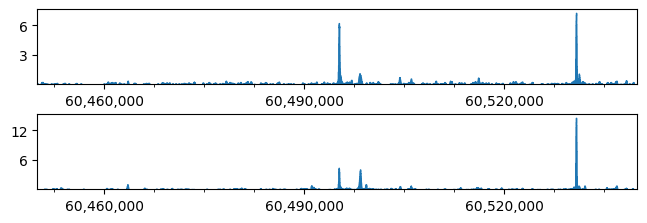

In [15]:
axes = plotter.plot_interval(data, fig_width=6, height_scale=1.5)

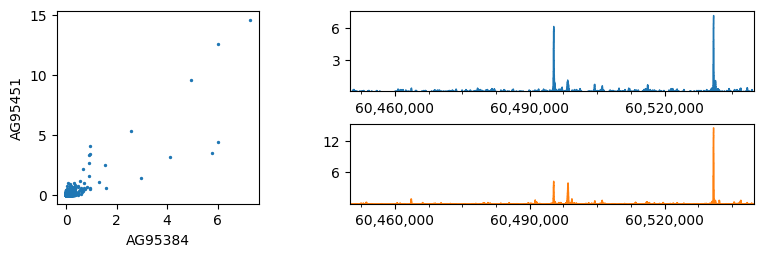

In [16]:
fig = plt.figure(figsize=(9, 2.5))
outer = fig.add_gridspec(1, 2, width_ratios=[1, 2], wspace=0.3)
side_ax = fig.add_subplot(outer[0, 0])
side_ax.scatter(data.AG95384.signal[::50], data.AG95451.signal[::50], s=2)
side_ax.set_xlabel('AG95384')
side_ax.set_ylabel('AG95451')
axes = plotter.plot_interval(data, subplot_spec=outer[0, 1], AG95451={'color': 'tab:orange'})